#  Script to demo the processing of the L Band of SAR

- It starts by setting up the directory paths and specifying parameters like the heading direction and polarimetric channel. 
- The script then loads various necessary datasets, including scene parameters, phase-to-height factors (kz), sensor trajectories, and digital terrain models (DTMs). 
- It reads Single Look Complex (SLC) images for the specified polarimetric channel and performs repeat-pass tomography to generate tomographic profiles both in the azimuth and ground range directions. 
- These profiles are visualized using matplotlib. Additionally, the script reads ancillary geocoding data from MetaSensing files, adjusting the data to match the scene parameters.
-  The processed data helps in understanding the vertical structure and spatial distribution of the observed scene in both azimuth and ground range dimensions.

1. **Scene Parameters**
   Scene parameters include metadata about the SAR acquisition, such as the number of samples (range dimension) and lines (azimuth dimension). These parameters are essential for correctly interpreting the SAR data and are usually stored in a separate file.

   - **NrTot**: Total number of range samples.
   - **NcTot**: Total number of azimuth lines.

2. **Phase-to-Height Factors (kz)**
   Phase-to-height factors, denoted as kz, are critical in SAR interferometry and tomography. They represent the relationship between the phase difference observed in SAR images and the height of the terrain. These factors are used to derive elevation information from phase data.

   - **kz**: A 3D array where each slice corresponds to the phase-to-height factors for a specific azimuth line and range sample.

3. **Sensor Trajectories**
   Sensor trajectories describe the flight path of the SAR platform (e.g., a satellite or an aircraft) during the data acquisition process. Accurate knowledge of the sensor's position and velocity is vital for precise geolocation and correction of motion-induced errors.

   - **Trajectories**: This includes information about the sensor's position (latitude, longitude, altitude) and i
\

Key Adjustments and Inline Comments (changes from matlab script) :
- Function Placeholder: The read_biomass_data function needs implementation based on the actual data format.
- Path Handling: Constructed using os.path.join for better path handling.
- Polarimetric and Heading Indices: Adjusted for 0-based indexing in Python.
- Scene Parameters: Loaded using scipy.io.loadmat.
- Tomographic Processing: Adjustments for handling complex numbers and numpy operations.
- Geocoding Data: Reading geocoding data from the NetCDF file using the netCDF4 library.
- Plotting: Visualization of tomographic data using matplotlib.

In [2]:
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import loadmat
from netCDF4 import Dataset

parent_path = '/home/grace.bcolverd/L/'

import sys 
sys.path.append('/home/grace.bcolverd/2024-ESL-BiomassSAR')
from src.fdlbiomass.utils import read_biomass_data

heading = 'NW'  # Either 'NW' (290°) or 'SE' (110°)
polarimetric_channel = 'HH'  # 'HH', 'HV' or 'VV'

pol_ind = {'HH': 0, 'HV': 1, 'VV': 2}[polarimetric_channel]

# Loading scene parameters
scene_params = loadmat(f'{parent_path}{heading}/Util/SLC/SceneParameters.mat')
ground_range_axis = scene_params['ground_range_axis'].squeeze()
azimuth_axis = scene_params['azimuth_axis'].squeeze()
N = scene_params['N'].item()
filenames_kz = scene_params['filenames_kz']
filenames_slc = scene_params['filenames_slc']

Ngr = len(ground_range_axis)
Naz = len(azimuth_axis)




# import os
# import numpy as np
# import matplotlib.pyplot as plt
# from scipy.io import loadmat
# from netCDF4 import Dataset





# # Define heading and polarimetric channel
# heading = 'NW'  # Either 'NW' (290°) or 'SE' (110°)
# polarimetric_channel = 'HH'  # 'HH', 'HV' or 'VV'

# # Determine the polarimetric index based on the channel
# if polarimetric_channel == 'HH':
#     pol_ind = 1
# elif polarimetric_channel == 'HV':
#     pol_ind = 2
# elif polarimetric_channel == 'VV':
#     pol_ind = 3

# # Loading

# Loading scene parameters
curr_fullpath = os.path.join(parent_path, heading, 'Util', 'SLC', 'SceneParameters.mat')
scene_parameters = loadmat(curr_fullpath)

ground_range_axis = scene_parameters['ground_range_axis'].squeeze()
azimuth_axis = scene_parameters['azimuth_axis'].squeeze()
Ngr = len(ground_range_axis)
Naz = len(azimuth_axis)

# Loading phase-to-height factors
kz = np.zeros((Ngr, Naz, scene_parameters['N'][0][0]), dtype=np.single)
for n in range(scene_parameters['N'][0][0]):
    # Ensure the filename is treated as a string
    filename_kz = scene_parameters['filenames_kz'][n][0]
    if isinstance(filename_kz, np.ndarray):
        filename_kz = str(filename_kz[0])  # Convert ndarray to string, assuming the actual string is the first element
    curr_fullpath = os.path.join(parent_path, heading, 'Util', 'SLC', 'kz', filename_kz)
    print(f'Loading {curr_fullpath}...')
    kz[:, :, n] = read_biomass_data(curr_fullpath, [], 2)
    print('done.')


# Loading sensor trajectories
curr_fullpath = os.path.join(parent_path, heading, 'Util', 'SLC', 'FocusingCenters.mat')
focusing_centers = loadmat(curr_fullpath)

# Loading DTMs
curr_fullpath = os.path.join(parent_path, heading, 'Util', 'SLC', 'MetaSensingDTM.mat')
meta_sensing_dtm = loadmat(curr_fullpath)
curr_fullpath = os.path.join(parent_path, heading, 'Util', 'SLC', 'TomoDTMsr.mat')
tomo_dtm_sr = loadmat(curr_fullpath)

# Loading SLC images
I = np.zeros((Ngr, Naz, scene_parameters['N'][0][0]), dtype=np.complex64)


for n in range(scene_parameters['N'][0][0]):
    curr_fullpath = os.path.join(parent_path, heading, 'SLC', 'PoliMi', scene_parameters['filenames_slc'][n, pol_ind-1][0])
    print(f'Loading {curr_fullpath}...')
    I[:, :, n] = read_biomass_data(curr_fullpath, [], 1)

    print('done.')








Loading /home/grace.bcolverd/L/NW/Util/SLC/kz/kz_20200914151609_2_1.4G_HH_31_pres_16_fdc_0.sar.sig.nc.dat...
done.
Loading /home/grace.bcolverd/L/NW/Util/SLC/kz/kz_20200914152810_2_1.4G_HH_31_pres_16_fdc_0.sar.sig.nc.dat...
done.
Loading /home/grace.bcolverd/L/NW/Util/SLC/kz/kz_20200914154009_2_1.4G_HH_31_pres_16_fdc_0.sar.sig.nc.dat...
done.
Loading /home/grace.bcolverd/L/NW/Util/SLC/kz/kz_20200914155209_2_1.4G_HH_31_pres_16_fdc_0.sar.sig.nc.dat...
done.
Loading /home/grace.bcolverd/L/NW/Util/SLC/kz/kz_20200914160410_2_1.4G_HH_31_pres_16_fdc_0.sar.sig.nc.dat...
done.
Loading /home/grace.bcolverd/L/NW/Util/SLC/kz/kz_20200914161710_2_1.4G_HH_31_pres_16_fdc_0.sar.sig.nc.dat...
done.
Loading /home/grace.bcolverd/L/NW/Util/SLC/kz/kz_20200914162909_2_1.4G_HH_31_pres_16_fdc_0.sar.tmb.tmr.sig.nc.dat...
done.
Loading /home/grace.bcolverd/L/NW/Util/SLC/kz/kz_20200914165409_2_1.4G_HH_31_pres_16_fdc_0.sar.sig.nc.dat...
done.
Loading /home/grace.bcolverd/L/NW/Util/SLC/kz/kz_20200914170609_2_1.4G_H

In [4]:
n_tomo

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1], dtype=uint8)

In [11]:
scene_params['monostatic_acquisition'].shape

(60, 1)

In [13]:

# Tomography
z_axis = np.arange(-60, 61)
Nz = len(z_axis)

monostatic_tomography = True
n_tomo = scene_params['monostatic_acquisition'].squeeze() if monostatic_tomography else ~scene_params['monostatic_acquisition'].squeeze()
print(n_tomo.shape)

# Azimuth profile
S = np.zeros((Nz, Naz))
gr_ind = round(Ngr/4)
F = np.sum(np.abs(I[gr_ind, :, n_tomo])**2, axis=1)

# Ground steering
# height diff between two dtms for the given ground index     , across whole azimuth length 
dtm_diff = (tomo_dtm_sr['TomoDTMsr'][gr_ind, :] - meta_sensing_dtm['MetaSensingDTM'][gr_ind, :])
print('dtm ' , dtm_diff.shape)
print(kz[gr_ind, :, n_tomo].shape)
# this kz[gr_ind, :, :] selects the corresponding vertical wavenumbers for the ground range index for all azimuth, then mult the  vertical wavenumbers by the height difference for each azimuth, creating a phase correction term.
# exp_term = np.exp(-1j * kz[gr_ind, :, n_tomo] * dtm_diff[:, np.newaxis])

# Print shapes for debugging
print("n_tomo shape:", n_tomo.shape)
print("kz shape:", kz.shape)
print("dtm_diff shape:", dtm_diff.shape)

# Transpose kz[gr_ind, :, n_tomo] to match dtm_diff
kz_slice = kz[gr_ind, :, n_tomo].T  # Now shape should be (9324, 60)

# Reshape dtm_diff to broadcast correctly
dtm_diff_reshaped = dtm_diff[:, np.newaxis]  # Shape becomes (9324, 1)

# Now perform the multiplication
exp_term = np.exp(-1j * kz_slice * dtm_diff_reshaped)

print('exp term shape:', exp_term.shape)


print('exp term ' , exp_term.shape)
# this selects a slice of the complex SAR image data I for gr_ind, all elements along the azimuth and tomographic dimensions for this ground range. mult by exp term (exp has all azimuth and all z for one gr ind) 
Igs = I[gr_ind, :, :] * exp_term

for z_ind in range(Nz):
    z = z_axis[z_ind]
    
    # This creates a complex exponential term for a specific height z, a  focusing term,  , used to "focus" the ground-steered data (Igs) to that height. 
    exp_z_term = np.exp(-1j * kz[gr_ind, :, n_tomo] * z)

    #  representing the sum for each azimuth position of the  ground-steered image data with exp z term 
    sum_term = np.sum(Igs * exp_z_term, axis=1)

    # np.abs(sum_term)**2 computes the squared magnitude of the complex values.   
    S[z_ind, :] = np.abs(sum_term)**2 / (F + np.finfo(float).eps)

plt.figure()
plt.imshow(S, extent=[azimuth_axis[0]*1e-3, azimuth_axis[-1]*1e-3, z_axis[0], z_axis[-1]], aspect='auto', origin='lower')
plt.colorbar()
plt.xlabel('Azimuth [km]')
plt.ylabel('[m]')
plt.plot(azimuth_axis*1e-3, np.zeros(Naz), '--k', linewidth=2)
plt.show()


(60,)
dtm  (9324,)
(60, 9324)
n_tomo shape: (60,)
kz shape: (1648, 9324, 60)
dtm_diff shape: (9324,)
exp term shape: (9324, 60)
exp term  (9324, 60)


ValueError: operands could not be broadcast together with shapes (9324,60) (60,9324) 

In [21]:
scene_params['filenames_slc'][n, pol_ind][0]

'BISAR_CPLX_20200914151609_2_1.4G_HH_31_pres_16_fdc_0.sar_refocCal.dat'

In [54]:
I.shape

(1648, 9324, 60)

In [26]:
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import loadmat
from netCDF4 import Dataset


# Change directory to parent folder and set paths
os.chdir('..')
parent_path = '/home/grace.bcolverd/L'


# Define heading and polarimetric channel
heading = 'NW'  # Either 'NW' (290°) or 'SE' (110°)
polarimetric_channel = 'HH'  # 'HH', 'HV' or 'VV'

# Determine the polarimetric index based on the channel
if polarimetric_channel == 'HH':
    pol_ind = 1
elif polarimetric_channel == 'HV':
    pol_ind = 2
elif polarimetric_channel == 'VV':
    pol_ind = 3

# Loading

# Loading scene parameters
curr_fullpath = os.path.join(parent_path, heading, 'Util', 'SLC', 'SceneParameters.mat')
scene_parameters = loadmat(curr_fullpath)

ground_range_axis = scene_parameters['ground_range_axis'].squeeze()
azimuth_axis = scene_parameters['azimuth_axis'].squeeze()
Ngr = len(ground_range_axis)
Naz = len(azimuth_axis)

# Loading phase-to-height factors
kz = np.zeros((Ngr, Naz, scene_parameters['N'][0][0]), dtype=np.single)
for n in range(scene_parameters['N'][0][0]):
    # Ensure the filename is treated as a string
    filename_kz = scene_parameters['filenames_kz'][n][0]
    if isinstance(filename_kz, np.ndarray):
        filename_kz = str(filename_kz[0])  # Convert ndarray to string, assuming the actual string is the first element
    curr_fullpath = os.path.join(parent_path, heading, 'Util', 'SLC', 'kz', filename_kz)
    print(f'Loading {curr_fullpath}...')
    kz[:, :, n] = read_biomass_data(curr_fullpath, [], 2)
    print('done.')


# Loading sensor trajectories
curr_fullpath = os.path.join(parent_path, heading, 'Util', 'SLC', 'FocusingCenters.mat')
focusing_centers = loadmat(curr_fullpath)

# Loading DTMs
curr_fullpath = os.path.join(parent_path, heading, 'Util', 'SLC', 'MetaSensingDTM.mat')
meta_sensing_dtm = loadmat(curr_fullpath)
curr_fullpath = os.path.join(parent_path, heading, 'Util', 'SLC', 'TomoDTMsr.mat')
tomo_dtm_sr = loadmat(curr_fullpath)

# Loading SLC images
I = np.zeros((Ngr, Naz, scene_parameters['N'][0][0]), dtype=np.complex64)


for n in range(scene_parameters['N'][0][0]):
    curr_fullpath = os.path.join(parent_path, heading, 'SLC', 'PoliMi', scene_parameters['filenames_slc'][n, pol_ind-1][0])
    print(f'Loading {curr_fullpath}...')
    I[:, :, n] = read_biomass_data(curr_fullpath, [], 1)

    print('done.')


Loading /home/grace.bcolverd/L/NW/Util/SLC/kz/kz_20200914151609_2_1.4G_HH_31_pres_16_fdc_0.sar.sig.nc.dat...
done.
Loading /home/grace.bcolverd/L/NW/Util/SLC/kz/kz_20200914152810_2_1.4G_HH_31_pres_16_fdc_0.sar.sig.nc.dat...
done.
Loading /home/grace.bcolverd/L/NW/Util/SLC/kz/kz_20200914154009_2_1.4G_HH_31_pres_16_fdc_0.sar.sig.nc.dat...
done.
Loading /home/grace.bcolverd/L/NW/Util/SLC/kz/kz_20200914155209_2_1.4G_HH_31_pres_16_fdc_0.sar.sig.nc.dat...
done.
Loading /home/grace.bcolverd/L/NW/Util/SLC/kz/kz_20200914160410_2_1.4G_HH_31_pres_16_fdc_0.sar.sig.nc.dat...
done.
Loading /home/grace.bcolverd/L/NW/Util/SLC/kz/kz_20200914161710_2_1.4G_HH_31_pres_16_fdc_0.sar.sig.nc.dat...
done.
Loading /home/grace.bcolverd/L/NW/Util/SLC/kz/kz_20200914162909_2_1.4G_HH_31_pres_16_fdc_0.sar.tmb.tmr.sig.nc.dat...
done.
Loading /home/grace.bcolverd/L/NW/Util/SLC/kz/kz_20200914165409_2_1.4G_HH_31_pres_16_fdc_0.sar.sig.nc.dat...
done.
Loading /home/grace.bcolverd/L/NW/Util/SLC/kz/kz_20200914170609_2_1.4G_H

In [27]:
scene_parameters['N'][0][0]

60

In [28]:


# Tomography
z_axis = np.arange(-60, 61)
Nz = len(z_axis)

monostatic_tomography = True
n_tomo = scene_params['monostatic_acquisition'].squeeze() if monostatic_tomography else ~scene_params['monostatic_acquisition'].squeeze()

# Azimuth profile
S = np.zeros((Nz, Naz))
gr_ind = round(Ngr/4)
F = np.sum(np.abs(I[gr_ind, :, n_tomo])**2, axis=1)

for z_ind, z in enumerate(z_axis):
    # Ground steering
    Igs = I[gr_ind, :, n_tomo] * np.exp(-1j * kz[gr_ind, :, n_tomo] * (tomo_dtm_sr['TomoDTMsr'][gr_ind, :] - meta_sensing_dtm['MetaSensingDTM'][gr_ind, :]))
    
    S[z_ind, :] = np.abs(np.sum(Igs * np.exp(-1j * kz[gr_ind, :, n_tomo] * z), axis=1))**2 / (F + np.finfo(float).eps)

# Plotting
plt.figure()
plt.imshow(S, extent=[scene_params['azimuth_axis'][0]*1e-3, scene_params['azimuth_axis'][-1]*1e-3, z_axis[0], z_axis[-1]], aspect='auto', origin='lower')
plt.colorbar()
plt.xlabel('Azimuth [km]')
plt.ylabel('[m]')
plt.plot(scene_params['azimuth_axis']*1e-3, np.zeros(Naz), '--k', linewidth=2)
plt.show()

ValueError: could not broadcast input array from shape (60,) into shape (9324,)

In [63]:
n_tomo

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1], dtype=uint8)

In [33]:
I[gr_ind, :, n_tomo].shape

(60, 9324)

In [41]:
kz[gr_ind, :, n_tomo].T.shape

(9324, 60)

In [38]:
dtm_diff[:, np.newaxis].shape

(9324, 1)

In [53]:
I.shape

(1648, 9324, 60)

In [51]:
I[gr_ind, :, :].shape

(9324, 60)

In [52]:
I[gr_ind, :, n_tomo].shape

(60, 9324)

In [59]:
n_tomo.sum()

30

In [58]:
scene_params['monostatic_acquisition'].squeeze

array([[0],
       [0],
       [0],
       [0],
       [0],
       [0],
       [0],
       [0],
       [0],
       [0],
       [0],
       [0],
       [0],
       [0],
       [0],
       [0],
       [0],
       [0],
       [0],
       [0],
       [0],
       [0],
       [0],
       [0],
       [0],
       [0],
       [0],
       [0],
       [0],
       [0],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1]], dtype=uint8)

In [61]:

I[gr_ind, :, :].shape

(9324, 60)

In [60]:
I[gr_ind, :, n_tomo].shape

(60, 9324)

In [62]:
n_tomo

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1], dtype=uint8)

I shape: (1648, 9324, 60)
kz shape: (1648, 9324, 60)
TomoDTMsr shape: (1648, 9324)
MetaSensingDTM shape: (1648, 9324)
F shape: (9324,)
dtm  (9324,)
exp term  (9324, 30)
igs shape  (9324, 30)
S shape: (121, 9324)


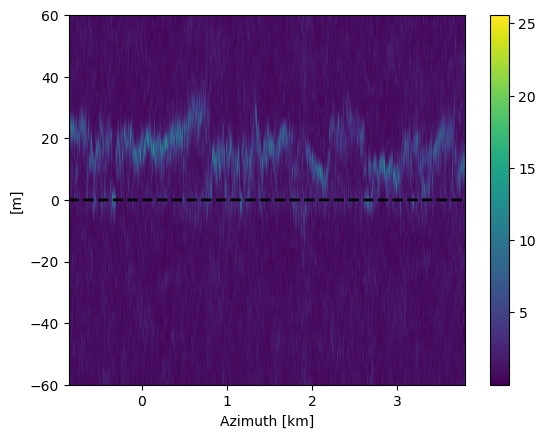

In [91]:

Naz = I.shape[1]
Ngr = I.shape[0]

print(f"I shape: {I.shape}")
print(f"kz shape: {kz.shape}")
print(f"TomoDTMsr shape: {tomo_dtm_sr['TomoDTMsr'].shape}")
print(f"MetaSensingDTM shape: {meta_sensing_dtm['MetaSensingDTM'].shape}")

# Tomography
z_axis = np.arange(-60, 61)
Nz = len(z_axis)

monostatic_tomography = True
n_tomo = scene_params['monostatic_acquisition'].squeeze() if monostatic_tomography else ~scene_params['monostatic_acquisition'].squeeze()
indices = np.where(n_tomo)[0]

# Azimuth profile
S = np.zeros((Nz, Naz))

gr_ind = round(Ngr/4)

# normalisation term ? shoud this be 2 x 2 or 1d array - unclear from matlab code - sum over 3rd dim that does not exist? sum over z axis?  single value for each azimuth 
F = np.sum(np.abs(I[gr_ind, :, :][:, indices])**2, axis=1)
print(f"F shape: {F.shape}")

# Ground steering
# height diff between two dtms for the given ground index     , across whole azimuth length 
dtm_diff = (tomo_dtm_sr['TomoDTMsr'][gr_ind, :] - meta_sensing_dtm['MetaSensingDTM'][gr_ind, :])
print('dtm ' , dtm_diff.shape)
# this kz[gr_ind, :, :] selects the corresponding vertical wavenumbers for the ground range index for all azimuth, then mult the  vertical wavenumbers by the height difference for each azimuth, creating a phase correction term.
exp_term = np.exp(-1j * kz[gr_ind, :, :][:, indices] * dtm_diff[:, np.newaxis])
print('exp term ' , exp_term.shape)
# this selects a slice of the complex SAR image data I for gr_ind, all elements along the azimuth and tomographic dimensions for this ground range. mult by exp term (exp has all azimuth and all z for one gr ind) 
Igs = I[gr_ind, :, :][:, indices] * exp_term
print('igs shape ' , Igs.shape)
for z_ind in range(Nz):
    z = z_axis[z_ind]

    # This creates a complex expnential term for oa specific height z, a  focusing term,  , used to "focus" the ground-steered data (Igs) to that height. 
    exp_z_term = np.exp(-1j * kz[gr_ind, :, :][:, indices] * z)
    
    #  representing the sum for each azimuth position of the  ground-steered image data with exp z term 
    sum_term = np.sum(Igs * exp_z_term, axis=1)

    # np.abs(sum_term)**2 computes the squared magnitude of the complex values.   
    S[z_ind, :] = np.abs(sum_term)**2 / (F + np.finfo(float).eps)

# The result S represents the intensity of the backscattered signal at height z for each azimuth position.
print(f"S shape: {S.shape}")

plt.figure()
plt.imshow(S, extent=[meta_sensing_dtm['azimuth_axis'][0, 0]*1e-3, meta_sensing_dtm['azimuth_axis'][0, -1]*1e-3, z_axis[0], z_axis[-1]],  aspect='auto',origin = 'lower')
plt.colorbar()
plt.xlabel('Azimuth [km]')
plt.ylabel('[m]')
plt.plot(meta_sensing_dtm['azimuth_axis'][0]*1e-3, np.zeros(Naz), '--k', linewidth=2)
plt.show()

In [ ]:
import numpy as np
import pandas as pd

def lidar_cube_to_table(lidar_cube):
    """
    Converts a LiDAR cube into a table with columns x, y, and lidar.

    Parameters:
    - lidar_cube: np.array of shape (x_dim, y_dim) where dimensions are (x, y, lidar)

    Returns:
    - pd.DataFrame with columns [x, y, lidar]
    """
    x_dim, y_dim = lidar_cube.shape
    records = []

    for x in range(x_dim):
        for y in range(y_dim):
            lidar_value = lidar_cube[x, y]
            records.append([x, y, lidar_value])

    # Create DataFrame
    df = pd.DataFrame(records, columns=['x', 'y', 'lidar'])
    return df

# Example usage

lidar_df = lidar_cube_to_table(LidarCHM)
print(lidar_df)


          x    y  lidar
0         0    0    NaN
1         0    1    NaN
2         0    2    NaN
3         0    3    NaN
4         0    4    NaN
...     ...  ...    ...
273835  325  835    NaN
273836  325  836    NaN
273837  325  837    NaN
273838  325  838    NaN
273839  325  839    NaN

[273840 rows x 3 columns]


In [ ]:
import numpy as np
import pandas as pd

def lidar_cube_to_table(lidar_cube):
    """
    Converts a LiDAR cube into a table with columns x, y, and lidar.

    Parameters:
    - lidar_cube: np.array of shape (x_dim, y_dim) where dimensions are (x, y, lidar)

    Returns:
    - pd.DataFrame with columns [x, y, lidar]
    """
    x_dim, y_dim = lidar_cube.shape
    records = []

    for x in range(x_dim):
        for y in range(y_dim):
            lidar_value = lidar_cube[x, y]
            records.append([x, y, lidar_value])

    # Create DataFrame
    df = pd.DataFrame(records, columns=['x', 'y', 'lidar'])
    return df

# Example usage

lidar_df = lidar_cube_to_table(LidarCHM)
print(lidar_df)


          x    y  lidar
0         0    0    NaN
1         0    1    NaN
2         0    2    NaN
3         0    3    NaN
4         0    4    NaN
...     ...  ...    ...
273835  325  835    NaN
273836  325  836    NaN
273837  325  837    NaN
273838  325  838    NaN
273839  325  839    NaN

[273840 rows x 3 columns]


In [ ]:
import numpy as np
import pandas as pd

def lidar_cube_to_table(lidar_cube):
    """
    Converts a LiDAR cube into a table with columns x, y, and lidar.

    Parameters:
    - lidar_cube: np.array of shape (x_dim, y_dim) where dimensions are (x, y, lidar)

    Returns:
    - pd.DataFrame with columns [x, y, lidar]
    """
    x_dim, y_dim = lidar_cube.shape
    records = []

    for x in range(x_dim):
        for y in range(y_dim):
            lidar_value = lidar_cube[x, y]
            records.append([x, y, lidar_value])

    # Create DataFrame
    df = pd.DataFrame(records, columns=['x', 'y', 'lidar'])
    return df

# Example usage

lidar_df = lidar_cube_to_table(LidarCHM)
print(lidar_df)


          x    y  lidar
0         0    0    NaN
1         0    1    NaN
2         0    2    NaN
3         0    3    NaN
4         0    4    NaN
...     ...  ...    ...
273835  325  835    NaN
273836  325  836    NaN
273837  325  837    NaN
273838  325  838    NaN
273839  325  839    NaN

[273840 rows x 3 columns]


In [ ]:

# Ground range profile
S = np.zeros((Nz, Ngr))
az_ind = round(Naz/3)
F = np.sum(np.abs(I[:, az_ind, n_tomo])**2, axis=1)

for z_ind in range(Nz):
    z = z_axis[z_ind]
    
    # Ground steering
    dtm_diff = tomo_dtm_sr['TomoDTMsr'][:, az_ind] - meta_sensing_dtm['MetaSensingDTM'][:, az_ind]
    Igs = I[:, az_ind, n_tomo] * np.exp(-1j * kz[:, az_ind, n_tomo] * dtm_diff[:, np.newaxis])
    
    S[z_ind, :] = np.abs(np.sum(Igs * np.exp(-1j * kz[:, az_ind, n_tomo] * z), axis=1))**2 / (F + np.finfo(float).eps)

plt.figure()
plt.imshow(S, extent=[ground_range_axis[0]*1e-3, ground_range_axis[-1]*1e-3, z_axis[0], z_axis[-1]], aspect='auto', origin='lower')
plt.colorbar()
plt.xlabel('Ground range [km]')
plt.ylabel('[m]')
plt.show()


In [ ]:

# Reading MetaSensing ancillary data
nc_file = f'{parent_path}{heading}/SLC/MetaSensing/SAR_CPLX_20200914160410_2_1.4G_HH_41_pres_16_fdc_0.sar.sig.nc' if heading == 'NW' else f'{parent_path}{heading}/SLC/MetaSensing/SAR_CPLX_20200914150909_2_1.4G_HH_41_pres_16_fdc_0.sar.sig.nc'

with nc.Dataset(nc_file) as nc_data:
    LatImage_azimuth_axis = nc_data.variables['CrossRange'][:]
    LatImage_ground_range_axis = nc_data.variables['GroundRange'][:]
    LatImage = nc_data.variables['LatImage'][:]

az_start_ind = np.argmin(np.abs(LatImage_azimuth_axis - azimuth_axis[0]))
az_stop_ind = np.argmin(np.abs(LatImage_azimuth_axis - azimuth_axis[-1]))
gr_start_ind = np.argmin(np.abs(LatImage_ground_range_axis - ground_range_axis[0]))
gr_stop_ind = np.argmin(np.abs(LatImage_ground_range_axis - ground_range_axis[-1]))

LatImage = LatImage[gr_start_ind:gr_stop_ind+1, az_start_ind:az_stop_ind+1]

In [3]:


# # Placeholder function to read biomass data (assumed to be implemented)
# def read_biomass_data(filepath, param, mode):
#     # Placeholder function
#     # You need to implement this based on the actual data format
#     pass

# Options

os.chdir('..')
parent_path = '/home/grace.bcolverd/L/'

# Define heading and polarimetric channel
heading = 'NW'  # Either 'NW' (290°) or 'SE' (110°)
polarimetric_channel = 'HH'  # 'HH', 'HV' or 'VV'

# Determine the polarimetric index based on the channel
if polarimetric_channel == 'HH':
    pol_ind = 1
elif polarimetric_channel == 'HV':
    pol_ind = 2
elif polarimetric_channel == 'VV':
    pol_ind = 3

# Loading

# Loading scene parameters
curr_fullpath = os.path.join(parent_path, heading, 'Util', 'SLC', 'SceneParameters.mat')
scene_parameters = loadmat(curr_fullpath)

ground_range_axis = scene_parameters['ground_range_axis'].squeeze()
azimuth_axis = scene_parameters['azimuth_axis'].squeeze()
Ngr = len(ground_range_axis)
Naz = len(azimuth_axis)

# # Loading phase-to-height factors
# kz = np.zeros((Ngr, Naz, scene_parameters['N'][0][0]), dtype=np.single)
# for n in range(scene_parameters['N'][0][0]):
#     curr_fullpath = os.path.join(parent_path, heading, 'Util', 'SLC', 'kz', scene_parameters['filenames_kz'][n][0])
#     print(f'Loading {curr_fullpath}...')
#     kz[:, :, n] = read_biomass_data(curr_fullpath, [], 2)
#     print('done.')

# # Loading sensor trajectories
# curr_fullpath = os.path.join(parent_path, heading, 'Util', 'SLC', 'FocusingCenters.mat')
# focusing_centers = loadmat(curr_fullpath)

# # Loading DTMs
# curr_fullpath = os.path.join(parent_path, heading, 'Util', 'SLC', 'MetaSensingDTM.mat')
# meta_sensing_dtm = loadmat(curr_fullpath)
# curr_fullpath = os.path.join(parent_path, heading, 'Util', 'SLC', 'TomoDTMsr.mat')
# tomo_dtm_sr = loadmat(curr_fullpath)

# # Loading SLC images
# I = np.zeros((Ngr, Naz, scene_parameters['N'][0][0]), dtype=np.complex64)
# for n in range(scene_parameters['N'][0][0]):
#     curr_fullpath = os.path.join(parent_path, heading, 'SLC', 'PoliMi', scene_parameters['filenames_slc'][n, pol_ind-1][0])
#     print(f'Loading {curr_fullpath}...')
#     I[:, :, n] = read_biomass_data(curr_fullpath, [], 1)
#     print('done.')

# Loading phase-to-height factors
kz = np.zeros((Ngr, Naz, scene_parameters['N'][0][0]), dtype=np.single)
for n in range(scene_parameters['N'][0][0]):
    # Ensure the filename is treated as a string
    filename_kz = scene_parameters['filenames_kz'][n][0]
    if isinstance(filename_kz, np.ndarray):
        filename_kz = str(filename_kz[0])  # Convert ndarray to string, assuming the actual string is the first element
    curr_fullpath = os.path.join(parent_path, heading, 'Util', 'SLC', 'kz', filename_kz)
    print(f'Loading {curr_fullpath}...')
    kz[:, :, n] = read_biomass_data(curr_fullpath, [], 2)
    print('done.')


# Loading sensor trajectories
curr_fullpath = os.path.join(parent_path, heading, 'Util', 'SLC', 'FocusingCenters.mat')
focusing_centers = loadmat(curr_fullpath)

# Loading DTMs
curr_fullpath = os.path.join(parent_path, heading, 'Util', 'SLC', 'MetaSensingDTM.mat')
meta_sensing_dtm = loadmat(curr_fullpath)
curr_fullpath = os.path.join(parent_path, heading, 'Util', 'SLC', 'TomoDTMsr.mat')
tomo_dtm_sr = loadmat(curr_fullpath)

# Loading SLC images
I = np.zeros((Ngr, Naz, scene_parameters['N'][0][0]), dtype=np.complex64)


for n in range(scene_parameters['N'][0][0]):
    curr_fullpath = os.path.join(parent_path, heading, 'SLC', 'PoliMi', scene_parameters['filenames_slc'][n, pol_ind-1][0])
    print(f'Loading {curr_fullpath}...')
    I[:, :, n] = read_biomass_data(curr_fullpath, [], 1)

    print('done.')

Loading /home/grace.bcolverd/L/NW/Util/SLC/kz/kz_20200914151609_2_1.4G_HH_31_pres_16_fdc_0.sar.sig.nc.dat...
done.
Loading /home/grace.bcolverd/L/NW/Util/SLC/kz/kz_20200914152810_2_1.4G_HH_31_pres_16_fdc_0.sar.sig.nc.dat...
done.
Loading /home/grace.bcolverd/L/NW/Util/SLC/kz/kz_20200914154009_2_1.4G_HH_31_pres_16_fdc_0.sar.sig.nc.dat...
done.
Loading /home/grace.bcolverd/L/NW/Util/SLC/kz/kz_20200914155209_2_1.4G_HH_31_pres_16_fdc_0.sar.sig.nc.dat...
done.
Loading /home/grace.bcolverd/L/NW/Util/SLC/kz/kz_20200914160410_2_1.4G_HH_31_pres_16_fdc_0.sar.sig.nc.dat...
done.
Loading /home/grace.bcolverd/L/NW/Util/SLC/kz/kz_20200914161710_2_1.4G_HH_31_pres_16_fdc_0.sar.sig.nc.dat...
done.
Loading /home/grace.bcolverd/L/NW/Util/SLC/kz/kz_20200914162909_2_1.4G_HH_31_pres_16_fdc_0.sar.tmb.tmr.sig.nc.dat...
done.
Loading /home/grace.bcolverd/L/NW/Util/SLC/kz/kz_20200914165409_2_1.4G_HH_31_pres_16_fdc_0.sar.sig.nc.dat...
done.
Loading /home/grace.bcolverd/L/NW/Util/SLC/kz/kz_20200914170609_2_1.4G_H

In [ ]:

# Tomography

# Local vertical axis (with respect to the local ground level)
z_axis = np.arange(-60, 61, 1)
Nz = len(z_axis)

monostatic_tomography = True
if monostatic_tomography:
    n_tomo = scene_parameters['monostatic_acquisition'].astype(bool)
else:
    n_tomo = ~scene_parameters['monostatic_acquisition'].astype(bool)


# Azimuth profile
S = np.zeros((Nz, Naz))
gr_ind = round(Ngr / 4)
F = np.sum(np.abs(I[gr_ind, :, n_tomo])**2, axis=2)

for z_ind in range(Nz):
    z = z_axis[z_ind]

    # Ground steering
    Igs = I[gr_ind, :, n_tomo] * np.exp(-1j * kz[gr_ind, :, n_tomo] * (tomo_dtm_sr['TomoDTMsr'][gr_ind, :] - meta_sensing_dtm['MetaSensingDTM'][gr_ind, :]))

    S[z_ind, :] = np.abs(np.sum(Igs * np.exp(-1j * kz[gr_ind, :, n_tomo] * z), axis=2))**2 / (F + np.finfo(float).eps)

plt.figure()
plt.imshow(S, aspect='auto', extent=[azimuth_axis[0]*1e-3, azimuth_axis[-1]*1e-3, z_axis[-1], z_axis[0]], origin='lower')
plt.xlabel('Azimuth [km]')
plt.ylabel('[m]')
plt.title('Azimuth Profile')
plt.colorbar()
plt.show()

# Ground range profile
S = np.zeros((Nz, Ngr))
az_ind = round(Naz / 3)
F = np.sum(np.abs(I[:, az_ind, n_tomo])**2, axis=2)

for z_ind in range(Nz):
    z = z_axis[z_ind]

    # Ground steering
    Igs = I[:, az_ind, n_tomo] * np.exp(-1j * kz[:, az_ind, n_tomo] * (tomo_dtm_sr['TomoDTMsr'][:, az_ind] - meta_sensing_dtm['MetaSensingDTM'][:, az_ind]))

    S[z_ind, :] = np.abs(np.sum(Igs * np.exp(-1j * kz[:, az_ind, n_tomo] * z), axis=2))**2 / (F + np.finfo(float).eps)

plt.figure()
plt.imshow(S.T, aspect='auto', extent=[ground_range_axis[0]*1e-3, ground_range_axis[-1]*1e-3, z_axis[-1], z_axis[0]], origin='lower')
plt.xlabel('Ground range [km]')
plt.ylabel('[m]')
plt.title('Ground Range Profile')
plt.colorbar()
plt.show()

# Reading MetaSensing ancillary data
if heading == 'NW':
    curr_fullpath = os.path.join(parent_path, heading, 'SLC', 'MetaSensing', 'SAR_CPLX_20200914160410_2_1.4G_HH_41_pres_16_fdc_0.sar.sig.nc')
elif heading == 'SE':
    curr_fullpath = os.path.join(parent_path, heading, 'SLC', 'MetaSensing', 'SAR_CPLX_20200914150909_2_1.4G_HH_41_pres_16_fdc_0.sar.sig.nc')

with Dataset(curr_fullpath, 'r') as ds:
    LatImage_azimuth_axis = ds.variables['CrossRange'][:]
    LatImage_ground_range_axis = ds.variables['GroundRange'][:]
    LatImage = ds.variables['LatImage'][:]

# Determine indices for slicing the MetaSensing data to match the scene parameters
az_start_ind = np.argmin(np.abs(LatImage_azimuth_axis - azimuth_axis[0]))
az_stop_ind = np.argmin(np.abs(LatImage_azimuth_axis - azimuth_axis[-1]))
gr_start_ind = np.argmin(np.abs(LatImage_ground_range_axis - ground_range_axis[0]))
gr_stop_ind = np.argmin(np.abs(LatImage_ground_range_axis - ground_range_axis[-1]))

LatImage = LatImage[gr_start_ind:gr_stop_ind+1, az_start_ind:az_stop_ind+1]
